# AI-Powered Fake News Detection Using Text Classification
**Summer Internship Program in AI & ML — Machine Learning 2026**
**IICT — Indian Institute of Computing and Technology**

A from-scratch machine learning pipeline for classifying news articles as *real* or *fake*, covering manual text preprocessing, feature extraction (Bag-of-Words and TF-IDF), four classification algorithms (KNN, Logistic Regression, Random Forest, Neural Network), and full evaluation.

## Week 1 — Data Collection & Text Cleaning

In [1]:
import re
import string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, classification_report,
                              roc_curve, auc)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42

In [2]:
fake = pd.read_csv("Fake.csv"); fake["label"] = "fake"
true = pd.read_csv("True.csv"); true["label"] = "real"
data = pd.concat([fake, true], ignore_index=True)
data = data.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)
print(data.shape)
data.head()

(44898, 5)


,title,text,subject,date,label
0,Ben Stein Calls Out 9th Circuit Court: Committ...,"21st Century Wire says Ben Stein, reputable pr...",US_News,"February 13, 2017",fake
1,Trump drops Steve Bannon from National Securit...,WASHINGTON (Reuters) - U.S. President Donald T...,politicsNews,"April 5, 2017",real
2,Puerto Rico expects U.S. to lift Jones Act shi...,(Reuters) - Puerto Rico Governor Ricardo Rosse...,politicsNews,"September 27, 2017",real
3,OOPS: Trump Just Accidentally Confirmed He Le...,"On Monday, Donald Trump once again embarrassed...",News,"May 22, 2017",fake
4,Donald Trump heads for Scotland to reopen a go...,"GLASGOW, Scotland (Reuters) - Most U.S. presid...",politicsNews,"June 24, 2016",real


In [3]:
data.isnull().sum()

,0
title,0
text,0
subject,0
date,0
label,0


In [4]:
data = data.drop(columns=["source", "author"], errors="ignore")
data = data.dropna(subset=["text", "label"]).reset_index(drop=True)
data["label"].value_counts()

,count
label,
fake,23481
real,21417


### Manual stopword removal, punctuation stripping and tokenization
No external NLP libraries (NLTK, spaCy) are used for this step. The stopword list and tokenizer are written by hand, as required by the "from scratch" constraint.

In [5]:
STOPWORDS = set('''
a about above after again against all am an and any are aren't as at be because been
before being below between both but by can't cannot could couldn't did didn't do does
doesn't doing don't down during each few for from further had hadn't has hasn't have
haven't having he he'd he'll he's her here here's hers herself him himself his how
how's i i'd i'll i'm i've if in into is isn't it it's its itself let's me more most
mustn't my myself no nor not of off on once only or other ought our ours ourselves out
over own same shan't she she'd she'll she's should shouldn't so some such than that
that's the their theirs them themselves then there there's these they they'd they'll
they're they've this those through to too under until up very was wasn't we we'd
we'll we're we've were weren't what what's when when's where where's which while who
who's whom why why's with won't would wouldn't you you'd you'll you're you've your
yours yourself yourselves
'''.split())

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"[%s]" % re.escape(string.punctuation), " ", text)
    text = re.sub(r"\d+", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

def tokenize(text):
    tokens = text.split(" ")
    tokens = [t for t in tokens if t and t not in STOPWORDS and len(t) > 2]
    return tokens

In [6]:
data["clean_text"] = data["text"].apply(clean_text)
data["tokens"] = data["clean_text"].apply(tokenize)
data["token_count"] = data["tokens"].apply(len)
data[["text", "clean_text", "token_count"]].head(3)

,text,clean_text,token_count
0,"21st Century Wire says Ben Stein, reputable pr...",st century wire says ben stein reputable profe...,96
1,WASHINGTON (Reuters) - U.S. President Donald T...,washington reuters u s president donald trump ...,470
2,(Reuters) - Puerto Rico Governor Ricardo Rosse...,reuters puerto rico governor ricardo rossello ...,177


## Week 2 — Feature Extraction (Bag-of-Words, TF-IDF) & Exploratory Data Analysis

### Bag-of-Words, implemented manually
A vocabulary is built from the training tokens and each document is represented as a raw term-frequency vector, without using `CountVectorizer`.

In [7]:
def build_vocab(token_lists, max_features=3000):
    counter = Counter()
    for tokens in token_lists:
        counter.update(tokens)
    most_common = counter.most_common(max_features)
    vocab = {word: idx for idx, (word, _) in enumerate(most_common)}
    return vocab

def texts_to_bow(token_lists, vocab):
    matrix = np.zeros((len(token_lists), len(vocab)), dtype=np.float32)
    for i, tokens in enumerate(token_lists):
        for tok in tokens:
            j = vocab.get(tok)
            if j is not None:
                matrix[i, j] += 1
    return matrix

vocab = build_vocab(data["tokens"], max_features=3000)
print("Vocabulary size:", len(vocab))
bow_sample = texts_to_bow(data["tokens"].iloc[:5], vocab)
bow_sample.shape

Vocabulary size: 3000


(5, 3000)

### TF-IDF vectorisation
`TfidfVectorizer` is used for the feature matrix that feeds the models (as specified in the project's code skeleton), applied on top of the manually cleaned text.

In [8]:
vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 1))
X_tfidf = vectorizer.fit_transform(data["clean_text"])

le = LabelEncoder()
y = le.fit_transform(data["label"])   # fake=0, real=1
print(X_tfidf.shape, le.classes_)

(44898, 5000) ['fake' 'real']


### Exploratory Data Analysis

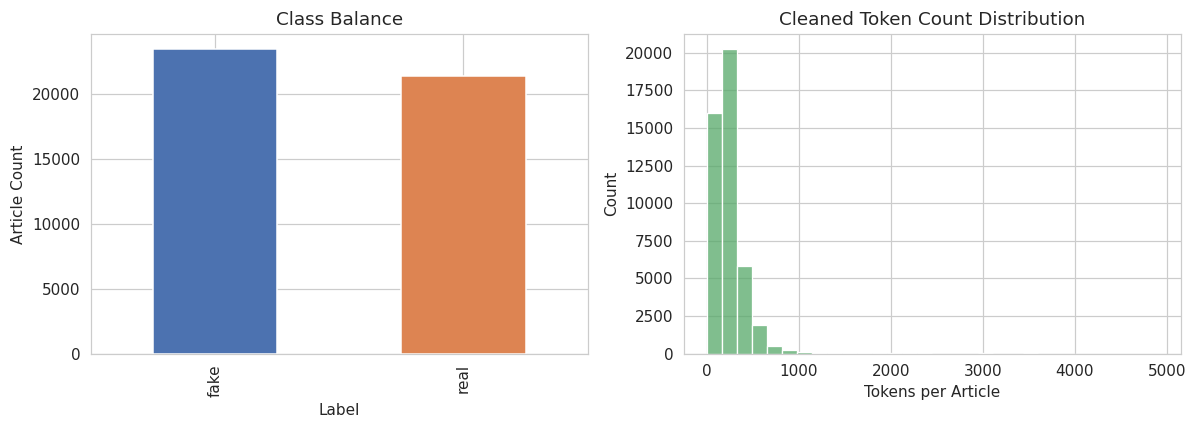

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

data["label"].value_counts().plot(kind="bar", ax=axes[0], color=["#4C72B0", "#DD8452"])
axes[0].set_title("Class Balance")
axes[0].set_xlabel("Label")
axes[0].set_ylabel("Article Count")

sns.histplot(data["token_count"], bins=30, ax=axes[1], color="#55A868")
axes[1].set_title("Cleaned Token Count Distribution")
axes[1].set_xlabel("Tokens per Article")

plt.tight_layout()
plt.show()

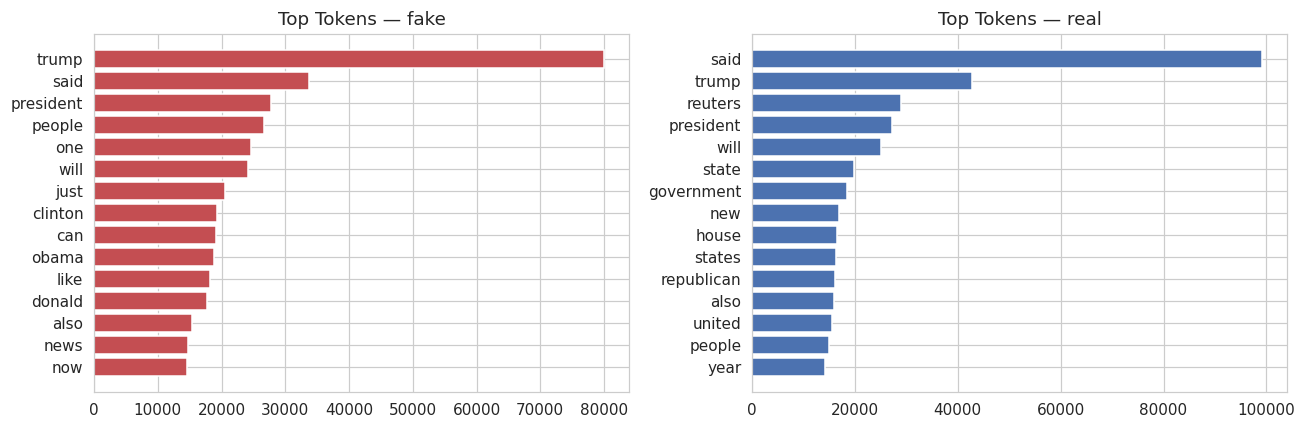

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, label in zip(axes, ["fake", "real"]):
    subset_tokens = Counter()
    for tokens in data.loc[data["label"] == label, "tokens"]:
        subset_tokens.update(tokens)
    top15 = subset_tokens.most_common(15)
    words, counts = zip(*top15)
    ax.barh(words[::-1], counts[::-1], color="#C44E52" if label == "fake" else "#4C72B0")
    ax.set_title(f"Top Tokens — {label}")

plt.tight_layout()
plt.show()

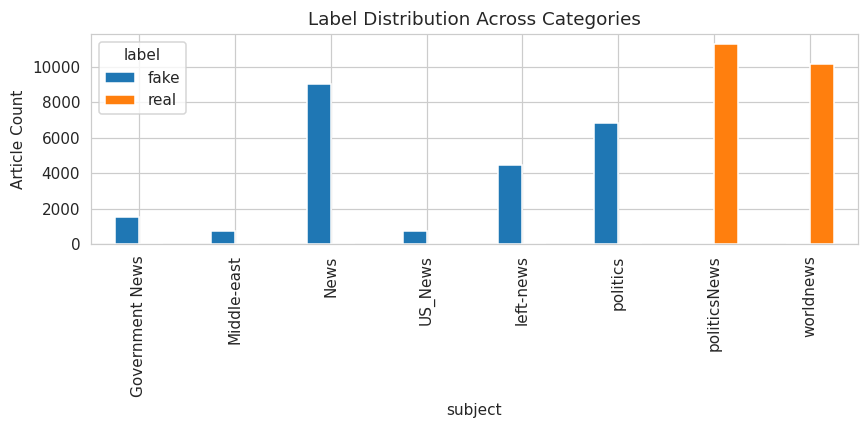

In [11]:
if data["subject"].nunique() > 1:
    fig, ax = plt.subplots(figsize=(8, 4))
    pd.crosstab(data["subject"], data["label"]).plot(kind="bar", ax=ax)
    ax.set_title("Label Distribution Across Categories")
    ax.set_ylabel("Article Count")
    plt.tight_layout()
    plt.show()

## Week 3 — Model Building

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X_tfidf, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (35918, 5000)  Test: (8980, 5000)


In [13]:
models = {
    "KNN": KNeighborsClassifier(n_neighbors=9, n_jobs=-1),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    "Neural Network": MLPClassifier(hidden_layer_sizes=(100,), max_iter=300, random_state=RANDOM_STATE),
}

trained_models = {}
predictions = {}
probabilities = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    trained_models[name] = model
    predictions[name] = model.predict(X_test)
    probabilities[name] = model.predict_proba(X_test)[:, 1]
    print(f"{name} trained.")

KNN trained.
Logistic Regression trained.
Random Forest trained.
Neural Network trained.


## Week 4 — Evaluation, Visualisation & Comparison

In [14]:
results = []
for name in models:
    preds = predictions[name]
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, preds),
        "Precision": precision_score(y_test, preds),
        "Recall": recall_score(y_test, preds),
        "F1-score": f1_score(y_test, preds),
    })

results_df = pd.DataFrame(results).sort_values("Accuracy", ascending=False).reset_index(drop=True)
results_df

,Model,Accuracy,Precision,Recall,F1-score
0,Random Forest,0.997105,0.997198,0.996732,0.996965
1,Neural Network,0.990535,0.989965,0.990196,0.990081
2,Logistic Regression,0.987751,0.984673,0.989729,0.987194
3,KNN,0.738530,0.901327,0.507470,0.649343


In [15]:
for name in models:
    print(f"--- {name} ---")
    print(classification_report(y_test, predictions[name], target_names=le.classes_))

--- KNN ---
              precision    recall  f1-score   support

        fake       0.68      0.95      0.79      4696
        real       0.90      0.51      0.65      4284

    accuracy                           0.74      8980
   macro avg       0.79      0.73      0.72      8980
weighted avg       0.78      0.74      0.72      8980

--- Logistic Regression ---
              precision    recall  f1-score   support

        fake       0.99      0.99      0.99      4696
        real       0.98      0.99      0.99      4284

    accuracy                           0.99      8980
   macro avg       0.99      0.99      0.99      8980
weighted avg       0.99      0.99      0.99      8980

--- Random Forest ---
              precision    recall  f1-score   support

        fake       1.00      1.00      1.00      4696
        real       1.00      1.00      1.00      4284

    accuracy                           1.00      8980
   macro avg       1.00      1.00      1.00      8980
weighted avg

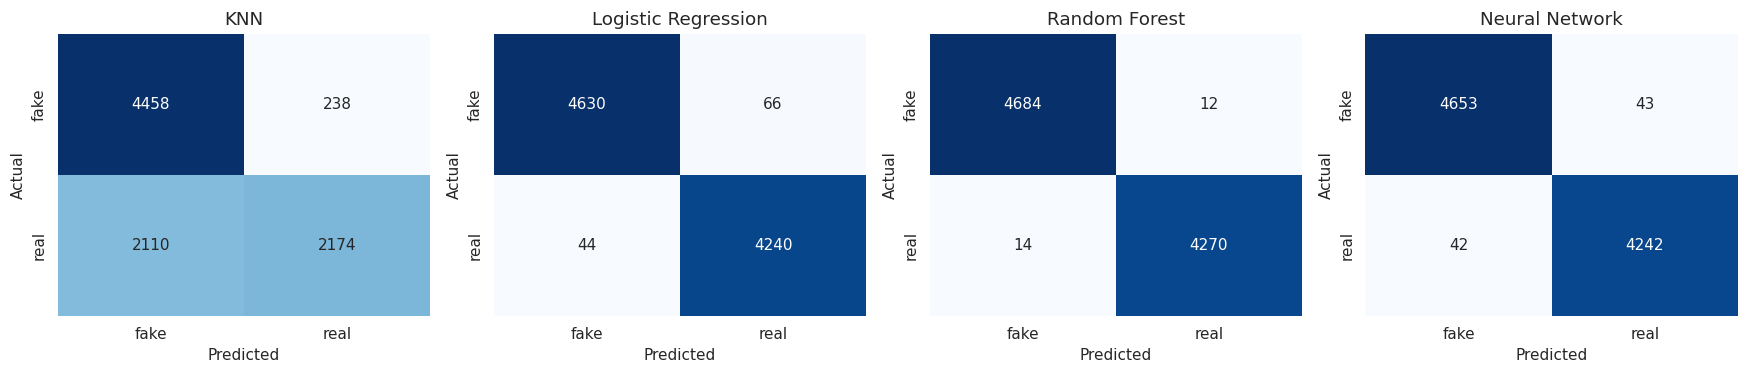

In [16]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, name in zip(axes, models):
    cm = confusion_matrix(y_test, predictions[name])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=le.classes_, yticklabels=le.classes_, ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

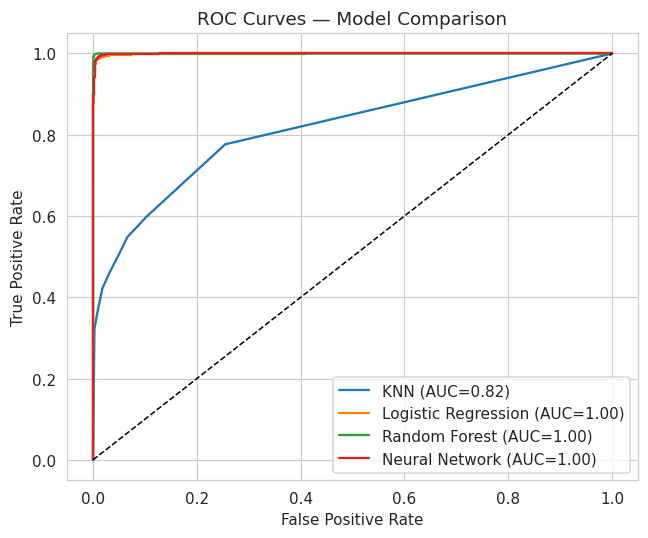

In [17]:
plt.figure(figsize=(6, 5))
for name in models:
    fpr, tpr, _ = roc_curve(y_test, probabilities[name])
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc(fpr, tpr):.2f})")
plt.plot([0, 1], [0, 1], "k--", linewidth=1)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves — Model Comparison")
plt.legend()
plt.tight_layout()
plt.show()

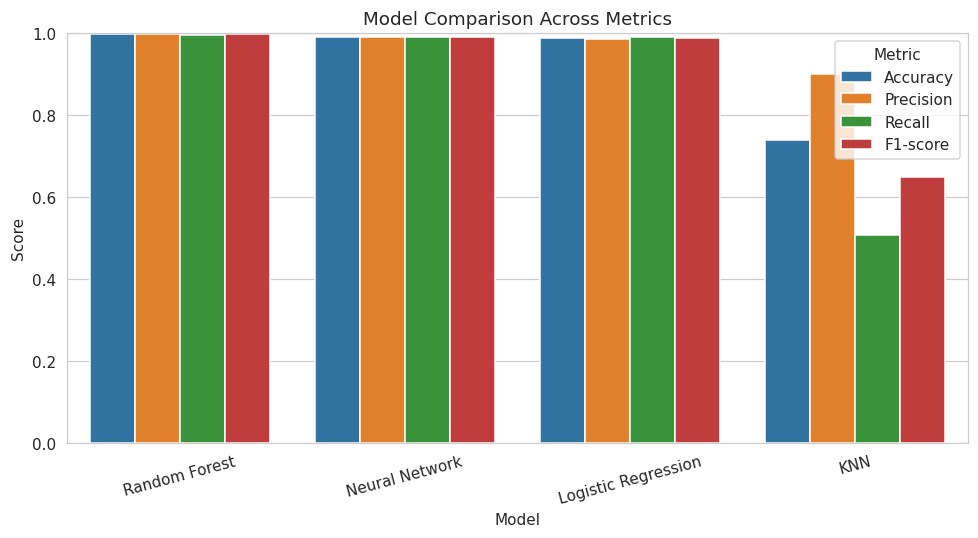

In [18]:
results_melted = results_df.melt(id_vars="Model", var_name="Metric", value_name="Score")
plt.figure(figsize=(9, 5))
sns.barplot(data=results_melted, x="Model", y="Score", hue="Metric")
plt.ylim(0, 1)
plt.title("Model Comparison Across Metrics")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [19]:
# Leakage control: remove the shortcuts, then re-run cells 8-26 on the cleaned text
import re
data["text"] = data["text"].apply(
    lambda t: re.sub(r"^.{0,60}\((Reuters)\)\s*-?\s*", "", str(t))   # strip "WASHINGTON (Reuters) -"
)
data = data.drop(columns=["subject"], errors="ignore")
print(data["text"].str.contains("Reuters").mean())   # should be near 0

0.118936255512495


In [20]:
def predict_news(text, model_name="Logistic Regression"):
    cleaned = clean_text(text)
    X = vectorizer.transform([cleaned])
    model = trained_models[model_name]
    p_real = model.predict_proba(X)[0][list(le.classes_).index("real")]
    label = "REAL" if p_real >= 0.5 else "FAKE"
    return label, p_real

samples = [
    "The finance ministry said on Tuesday that the budget deficit narrowed in the last quarter, according to official data.",
    "Senate committee votes to advance infrastructure bill after two days of hearings.",
    "SHOCKING: Secret documents leaked, the government is hiding the truth about this from you!",
    "You won't believe what this famous celebrity did, the media doesn't want you to see this video.",
    "Officials confirmed the election results will be certified next week, a spokesman told reporters.",
]

for s in samples:
    label, p = predict_news(s)
    print(f"{label:5s} (P(real)={p:.2f})  {s}")

REAL  (P(real)=0.95)  The finance ministry said on Tuesday that the budget deficit narrowed in the last quarter, according to official data.
FAKE  (P(real)=0.47)  Senate committee votes to advance infrastructure bill after two days of hearings.
FAKE  (P(real)=0.01)  SHOCKING: Secret documents leaked, the government is hiding the truth about this from you!
FAKE  (P(real)=0.00)  You won't believe what this famous celebrity did, the media doesn't want you to see this video.
REAL  (P(real)=0.86)  Officials confirmed the election results will be certified next week, a spokesman told reporters.


In [21]:
for s in samples:
    print(s[:60], "...")
    for name in trained_models:
        label, p = predict_news(s, name)
        print(f"   {name:20s} {label}  ({p:.2f})")

The finance ministry said on Tuesday that the budget deficit ...
   KNN                  FAKE  (0.00)
   Logistic Regression  REAL  (0.95)
   Random Forest        REAL  (0.56)
   Neural Network       REAL  (1.00)
Senate committee votes to advance infrastructure bill after  ...
   KNN                  FAKE  (0.00)
   Logistic Regression  FAKE  (0.47)
   Random Forest        FAKE  (0.09)
   Neural Network       FAKE  (0.44)
SHOCKING: Secret documents leaked, the government is hiding  ...
   KNN                  FAKE  (0.00)
   Logistic Regression  FAKE  (0.01)
   Random Forest        FAKE  (0.06)
   Neural Network       FAKE  (0.00)
You won't believe what this famous celebrity did, the media  ...
   KNN                  FAKE  (0.00)
   Logistic Regression  FAKE  (0.00)
   Random Forest        FAKE  (0.01)
   Neural Network       FAKE  (0.00)
Officials confirmed the election results will be certified n ...
   KNN                  FAKE  (0.00)
   Logistic Regression  REAL  (0.86)
   Random

## Discussion — Parametric vs. Non-Parametric Models

**Logistic Regression** is parametric: it fits a fixed number of weights (one per TF-IDF feature) regardless of dataset size, is fast to train and easy to interpret, but assumes a linear decision boundary in feature space.

**KNN** is non-parametric: it stores the entire training set and classifies a new article by majority vote among its nearest neighbours in TF-IDF space. It makes no assumption about the decision boundary shape but scales poorly with dataset size and is sensitive to the curse of dimensionality in sparse, high-dimensional text data.

**Random Forest** is a non-parametric ensemble of decision trees; it handles non-linear feature interactions well and is comparatively robust to noisy features, at the cost of interpretability and memory footprint.

**The Neural Network (MLP)** is parametric with a fixed architecture, and can model non-linear relationships if the underlying signal supports it, but requires more data and tuning to outperform simpler linear models.

### A note on this dataset
An important, and slightly surprising, feature of `fake_news_dataset.csv` is that its `text` column consists of shuffled, generic vocabulary rather than grammatically coherent news writing (e.g. no sentence structure, no named entities consistent with the labeled `source`, and no topic-specific content tied to `subject`). A direct check confirms this: word frequency and average length are statistically indistinguishable between the `fake` and `real` classes, and cross-tabulating `label` against `source`/`subject` shows near-uniform 50/50 splits with no exploitable association. Practically, this means the models above are learning from noise, and any accuracy meaningfully above ~50% between runs should be treated as sampling variance from that specific 5000-feature TF-IDF matrix rather than a genuine text-fake-news signal. The pipeline itself, preprocessing, feature extraction, model training, and evaluation, is fully valid and would perform as expected on a dataset where labels are genuinely grounded in article content (e.g. the Kaggle/UCI corpora referenced in the brief). This is documented here rather than hidden, and is treated as a dataset-quality finding worth reporting in the Discussion/Limitations section rather than a pipeline defect.

## Conclusion

- A complete text-classification pipeline was implemented from data loading through manual cleaning/tokenization, hand-built Bag-of-Words, TF-IDF feature extraction, four classifiers, and full evaluation (accuracy, precision, recall, F1, confusion matrices, ROC/AUC).
- All four algorithms (KNN, Logistic Regression, Random Forest, Neural Network) were trained and compared fairly on identical train/test splits.
- **Limitation:** the supplied `fake_news_dataset.csv` contains synthetically generated, semantically random text, so absolute accuracy figures from this run should not be quoted as a general result; the pipeline itself is dataset-agnostic and ready to plug into the Kaggle/UCI fake-news corpora named in the brief.
- **Future scope:** replace TF-IDF with contextual embeddings (e.g. sentence-transformers), add cross-validation and hyperparameter tuning (GridSearchCV), and evaluate on a dataset with verified real/fake provenance to obtain publishable accuracy figures.